# Классификация книг Goodreads по среднему рейтингу
Датасет: `book1-100k.csv` (книги с сайта Goodreads).

## 0. Описание задачи
В датасете 58 292 книги. Для каждой есть название, автор, издательство, язык, число страниц, дата публикации, число текстовых отзывов (CountsOfReview), а также распределение оценок от 1 до 5 (RatingDist1..5, RatingDistTotal) и средний рейтинг Rating.

Задача — бинарная классификация. По «внешним» характеристикам книги (число страниц, год и месяц издания, издательство, язык, популярность) предсказать, получит ли она высокий рейтинг:

| класс | условие на Rating |
|---|---|
| 0 — «обычная» книга | Rating < 4.0 |
| 1 — «высоко оценённая» книга | Rating ≥ 4.0 |

Порог 4.0 («четыре звезды и выше») — естественная граница на пятибалльной шкале; он делит данные на две достаточно крупные части (примерно 57 % / 43 %), так что дисбаланса классов практически нет.

**Важные договорённости (чтобы не было утечки данных):**
* Столбцы `RatingDist1…RatingDist5` не используются как признаки: средний рейтинг вычисляется из них напрямую, и модель просто «подсмотрела» бы ответ.
* Книги с `Rating = 0` — это книги, у которых нет ни одной оценки (`RatingDistTotal = 0`). Рейтинга у них фактически нет, поэтому они исключаются из задачи.
* Из `RatingDistTotal` берётся только общее число оценок (мера популярности книги), оно не раскрывает средний балл.

## 1. Чтение данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
RS = 42

df = pd.read_csv("book1-100k.csv")
print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (58292, 18)


,Id,Name,RatingDist1,pagesNumber,RatingDist4,RatingDistTotal,PublishMonth,PublishDay,Publisher,CountsOfReview,PublishYear,Language,Authors,Rating,RatingDist2,RatingDist5,ISBN,RatingDist3
0,1,"Harry Potter and the Half-Blood Prince (Harry Potter, #6)",1:9896,652,4:556485,total:2298124,16,9,Scholastic Inc.,28062,2006,eng,J.K. Rowling,4.57,2:25317,5:1546466,NaN,3:159960
1,2,"Harry Potter and the Order of the Phoenix (Harry Potter, #5)",1:12455,870,4:604283,total:2358637,1,9,Scholastic Inc.,29770,2004,eng,J.K. Rowling,4.50,2:37005,5:1493113,0439358078,3:211781
2,3,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)",1:108202,309,4:1513191,total:6587388,1,11,Scholastic Inc,75911,2003,eng,J.K. Rowling,4.47,2:130310,5:4268227,NaN,3:567458
3,4,"Harry Potter and the Chamber of Secrets (Harry Potter, #2)",1:11896,352,4:706082,total:2560657,1,11,Scholastic,244,2003,eng,J.K. Rowling,4.42,2:49353,5:1504505,0439554896,3:288821
4,5,"Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)",1:10128,435,4:630534,total:2610317,1,5,Scholastic Inc.,37093,2004,eng,J.K. Rowling,4.57,2:24849,5:1749958,043965548X,3:194848


In [ ]:
df.dtypes

Id                   int64
Name                   str
RatingDist1            str
pagesNumber          int64
RatingDist4            str
RatingDistTotal        str
PublishMonth         int64
PublishDay           int64
Publisher              str
CountsOfReview       int64
PublishYear          int64
Language               str
Authors                str
Rating             float64
RatingDist2            str
RatingDist5            str
ISBN                   str
RatingDist3            str
dtype: object

Столбцы `RatingDist*` записаны строками вида `"5:1546466"` — вытащим число. Также в данных есть ошибка: в `PublishMonth` встречаются значения до 31, а в `PublishDay` — только до 12. Очевидно, эти два столбца перепутаны местами.

In [ ]:
print("max PublishMonth:", df.PublishMonth.max(), "| max PublishDay:", df.PublishDay.max())
df = df.rename(columns={"PublishMonth": "PublishDay", "PublishDay": "PublishMonth"})   # меняем местами
print("после исправления: max Month =", df.PublishMonth.max(), ", max Day =", df.PublishDay.max())

df["RatingsTotal"] = df["RatingDistTotal"].str.split(":").str[1].astype(int)
print("Книг без единой оценки:", (df.RatingsTotal == 0).sum(), "| из них с Rating == 0:", ((df.RatingsTotal == 0) & (df.Rating == 0)).sum())

df = df[df.RatingsTotal > 0].copy()          # книги без оценок исключаем
print("Осталось книг:", len(df))

df["target"] = (df.Rating >= 4.0).astype(int)
df["target"].value_counts().sort_index()

max PublishMonth: 31 | max PublishDay: 12
после исправления: max Month = 12 , max Day = 31
Книг без единой оценки: 3479 | из них с Rating == 0: 3479
Осталось книг: 54813


target
0    31149
1    23664
Name: count, dtype: int64

## 2. Разбиение на обучающую и тестовую выборки
Разбиваем до любых вычислений статистик, заполнения пропусков и нормализации — всё это будем «обучать» только на обучающей выборке, чтобы информация из теста не попала в модель. Используем стратификацию по классу (доли классов в train и test одинаковые). Пропорция 80 % / 20 %.

In [ ]:
feature_cols = ["pagesNumber", "PublishYear", "PublishMonth", "CountsOfReview", "RatingsTotal", "Language", "Publisher"]
X = df[feature_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()
print("train:", X_train.shape, " test:", X_test.shape)
print("доли классов train:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("доли классов test: ", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

train: (43850, 7)  test: (10963, 7)
доли классов train: {0: 0.568, 1: 0.432}
доли классов test:  {0: 0.568, 1: 0.432}


Остальные столбцы (`Id`, `Name`, `ISBN`, `Authors`, `PublishDay`) в признаки не берём:
* `Id`, `ISBN`, `Name` — идентификаторы/уникальные тексты, закономерности по ним искать бессмысленно;
* `Authors` — 28 тыс. разных значений на 58 тыс. книг, у большинства авторов 1–2 книги, one-hot превратил бы признак в десятки тысяч столбцов;
* `PublishDay` — день месяца, по смыслу не должен влиять на рейтинг (проверим по корреляции ниже).

## 3. Визуализация и основные характеристики
Все описательные статистики считаем только по **обучающей** выборке.

In [ ]:
train = X_train.copy()
train["target"] = y_train
train["Rating"] = df.loc[train.index, "Rating"]
train["PublishDay"] = df.loc[train.index, "PublishDay"]

num_cols = ["pagesNumber", "PublishYear", "PublishMonth", "CountsOfReview", "RatingsTotal"]
train[num_cols + ["Rating"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pagesNumber,43850.0,295.66,245.89,0.0,173.00,256.00,368.00,23931.0
PublishYear,43850.0,1999.72,12.83,162.0,1997.00,2002.00,2005.00,3002.0
PublishMonth,43850.0,6.42,3.54,1.0,3.00,6.00,10.00,12.0
CountsOfReview,43850.0,160.46,1351.62,0.0,1.00,6.00,37.00,94850.0
RatingsTotal,43850.0,18207.04,155331.38,1.0,19.00,175.00,1950.75,6622480.0
Rating,43850.0,3.89,0.43,1.0,3.69,3.93,4.13,5.0


**Интерпретация описательных статистик.** По числовым признакам видно, что данные содержат явные ошибки и тяжёлые хвосты:
* `pagesNumber`: медиана ≈ 250 страниц, но минимум 0, а максимум — около 24 тысяч страниц (это не одна книга, а, скорее всего, многотомник или ошибка ввода);
* `PublishYear`: минимум 162 и максимум 3002 — невозможные годы;
* `CountsOfReview` и `RatingsTotal`: среднее намного больше медианы, а стандартное отклонение в десятки раз больше медианы. Распределения очень скошены вправо — у нескольких бестселлеров миллионы оценок, у большинства книг — единицы или десятки.
* средний `Rating` ≈ 3.9 при небольшом разбросе (std ≈ 0.4).

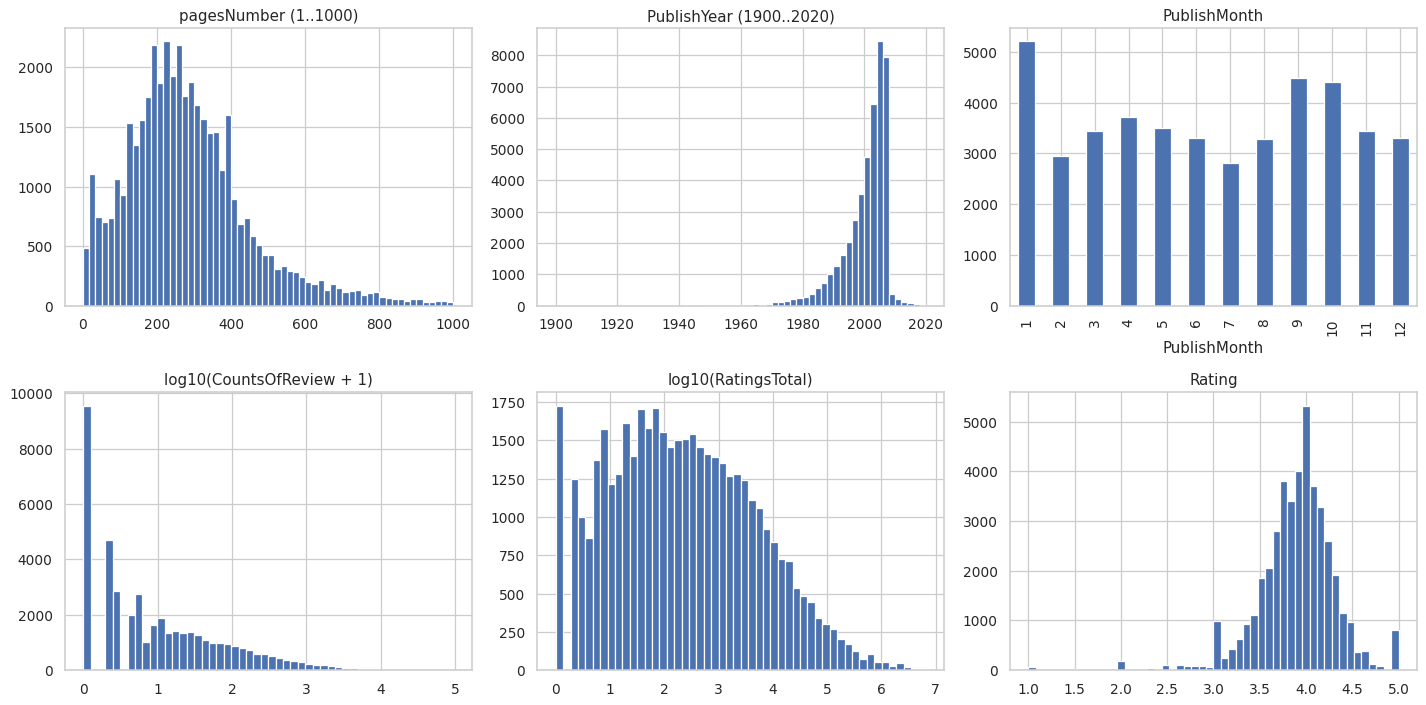

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
train.loc[train.pagesNumber.between(1, 1000), "pagesNumber"].hist(bins=60, ax=axes[0, 0]); axes[0, 0].set_title("pagesNumber (1..1000)")
train.loc[train.PublishYear.between(1900, 2020), "PublishYear"].hist(bins=60, ax=axes[0, 1]); axes[0, 1].set_title("PublishYear (1900..2020)")
train.PublishMonth.value_counts().sort_index().plot.bar(ax=axes[0, 2]); axes[0, 2].set_title("PublishMonth")
np.log10(train.CountsOfReview + 1).hist(bins=50, ax=axes[1, 0]); axes[1, 0].set_title("log10(CountsOfReview + 1)")
np.log10(train.RatingsTotal).hist(bins=50, ax=axes[1, 1]); axes[1, 1].set_title("log10(RatingsTotal)")
train.Rating.hist(bins=50, ax=axes[1, 2]); axes[1, 2].set_title("Rating")
plt.tight_layout(); plt.show()

Гистограммы подтверждают сказанное: число отзывов и оценок удобно смотреть в логарифмической шкале (там распределения близки к колоколообразным). Основная масса книг издана в 1990–2010-х годах. Рейтинг сосредоточен около 3.7–4.2 с «хвостом» влево (малое число очень плохо оценённых книг).

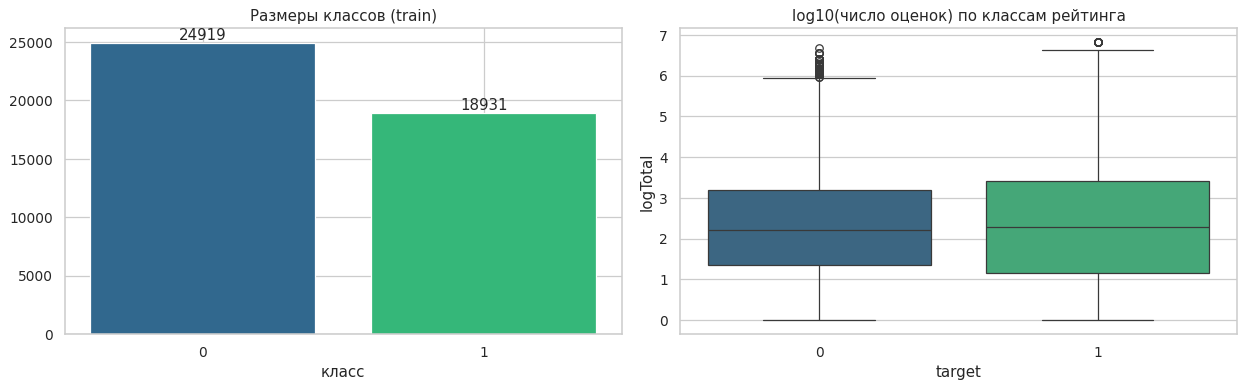

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cls_counts = train.target.value_counts().sort_index()
axes[0].bar(cls_counts.index.astype(str), cls_counts.values, color=sns.color_palette("viridis", 2))
axes[0].set_title("Размеры классов (train)"); axes[0].set_xlabel("класс")
for i, v in enumerate(cls_counts.values): axes[0].text(i, v, str(v), ha="center", va="bottom")

plot_df = train.assign(logTotal=np.log10(train.RatingsTotal))
sns.boxplot(data=plot_df, x="target", y="logTotal", hue="target", legend=False, ax=axes[1], palette="viridis")
axes[1].set_title("log10(число оценок) по классам рейтинга")
plt.tight_layout(); plt.show()

Классы: 57 % книг с рейтингом ниже 4.0 и 43 % — с рейтингом 4.0 и выше. Дисбаланс небольшой, специальной борьбы с ним не требуется. По боксплоту видно, что распределения числа оценок в двух классах почти совпадают (медианы отличаются слабо), то есть популярность книги сама по себе почти не разделяет классы. Высокой точности ждать не стоит.

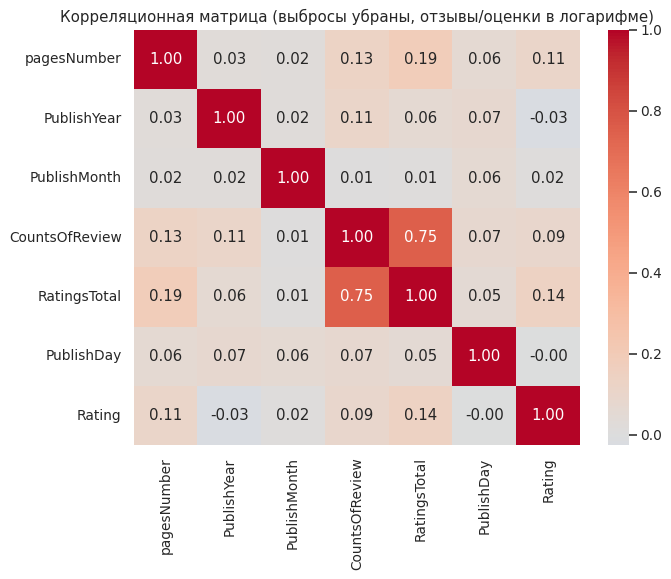

In [ ]:
corr_df = train[num_cols + ["PublishDay", "Rating"]].copy()
corr_df["PublishYear"] = corr_df["PublishYear"].where(corr_df.PublishYear.between(1900, 2020))
corr_df["pagesNumber"] = corr_df["pagesNumber"].where(corr_df.pagesNumber.between(1, 2000))
corr_df["CountsOfReview"] = np.log1p(corr_df.CountsOfReview)
corr_df["RatingsTotal"] = np.log(corr_df.RatingsTotal)
corr = corr_df.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица (выбросы убраны, отзывы/оценки в логарифме)")
plt.show()

**Интерпретация корреляций.**
* Самая сильная связь — между `CountsOfReview` и `RatingsTotal` (≈ 0.75 после логарифмирования): чем больше у книги оценок, тем больше и текстовых отзывов. Это два измерения одной и той же «популярности».
* С самим `Rating` все признаки связаны слабо (|r| ≲ 0.15). Чуть заметнее — число оценок (≈ 0.14), число страниц (≈ 0.10) и число отзывов (≈ 0.09); год и месяц издания практически не связаны с рейтингом.
* `PublishDay` не связан ни с чем (r ≈ 0), что подтверждает решение его не использовать.

Слабые связи означают, что задача по этим признакам объективно трудная.

## 4. Выбросы
Мы нашли такие аномалии:
* `pagesNumber = 0` — страницы не указаны (на самом деле пропуск, закодированный нулём);
* `pagesNumber > 2000` — многотомные издания/ошибки ввода;
* `PublishYear` вне диапазона 1900–2020 — невозможные значения (162, 3002 и т. п.);
* очень тяжёлые хвосты у `CountsOfReview` и `RatingsTotal` (но это настоящие данные, а не ошибки).

Что делаем: явно некорректные значения (страницы 0 или >2000, год вне 1900–2020) объявляем пропусками и заменим на медиану обучающей выборки в следующем шаге. Для `CountsOfReview` и `RatingsTotal` строки не удаляем, а применяем преобразование `log(1+x)`, которое сжимает хвост — и для метода ближайших соседей выбросы перестают «растягивать» шкалу.

In [ ]:
def bad_mask(d):
    return {
        "pagesNumber == 0": (d.pagesNumber == 0).sum(),
        "pagesNumber > 2000": (d.pagesNumber > 2000).sum(),
        "PublishYear < 1900": (d.PublishYear < 1900).sum(),
        "PublishYear > 2020": (d.PublishYear > 2020).sum(),
    }
print("train:", bad_mask(X_train))
print("test: ", bad_mask(X_test))

def mark_outliers(d):
    d = d.copy()
    d.loc[(d.pagesNumber <= 0) | (d.pagesNumber > 2000), "pagesNumber"] = np.nan
    d.loc[(d.PublishYear < 1900) | (d.PublishYear > 2020), "PublishYear"] = np.nan
    return d

X_train = mark_outliers(X_train)
X_test  = mark_outliers(X_test)

train: {'pagesNumber == 0': np.int64(408), 'pagesNumber > 2000': np.int64(57), 'PublishYear < 1900': np.int64(2), 'PublishYear > 2020': np.int64(1)}
test:  {'pagesNumber == 0': np.int64(106), 'pagesNumber > 2000': np.int64(20), 'PublishYear < 1900': np.int64(0), 'PublishYear > 2020': np.int64(0)}


## 5. Пропущенные значения

In [ ]:
pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()})

,train,test
pagesNumber,465,126
PublishYear,3,0
PublishMonth,0,0
CountsOfReview,0,0
RatingsTotal,0,0
Language,27635,6953
Publisher,383,74


Пропуски:
* `Language` — пропущен у ≈ 63 % книг. Выбрасывать эти строки нельзя (потеряем почти всё), поэтому пропуск превращаем в отдельную категорию `"unknown"` — само отсутствие языка может нести информацию;
* `Publisher` — немного пропусков (< 1 %), та же стратегия `"unknown"`;
* `pagesNumber`, `PublishYear` — пропуски появились после обработки выбросов; заполняем медианой обучающей выборки (медиана устойчива к выбросам). Эти же значения используем для тестовой выборки.

In [ ]:
medians = X_train[["pagesNumber", "PublishYear"]].median()
print("медианы по train:", medians.to_dict())

def fill_missing(d):
    d = d.copy()
    d[["pagesNumber", "PublishYear"]] = d[["pagesNumber", "PublishYear"]].fillna(medians)
    d["Language"]  = d["Language"].fillna("unknown")
    d["Publisher"] = d["Publisher"].fillna("unknown")
    return d

X_train = fill_missing(X_train)
X_test  = fill_missing(X_test)
print("Пропусков осталось: train =", X_train.isna().sum().sum(), ", test =", X_test.isna().sum().sum())

медианы по train: {'pagesNumber': 257.0, 'PublishYear': 2002.0}
Пропусков осталось: train = 0 , test = 0


## 6. Категориальные признаки
Категориальные признаки — `Language` и `Publisher`. Метод ближайших соседей работает с расстояниями, поэтому порядковое кодирование (1, 2, 3, …) не подходит — оно придумало бы несуществующий порядок. Используем one-hot кодирование.

Но у `Publisher` 7 тысяч значений, а у `Language` — десятки, большинство из которых очень редкие. Чтобы не получить тысячи столбцов:
* `Language`: оставляем `eng`, `en-US`, `en-GB`, `spa`, `fre`, `ger`, `unknown`, все остальные → `other`;
* `Publisher`: оставляем 10 самых частых издательств в обучающей выборке, остальные → `other`, пропуск → `unknown`.

In [ ]:
print(X_train.Language.value_counts().head(10))
print()
print(X_train.Publisher.value_counts().head(12))

Language
unknown    27635
eng        12812
en-US       1940
spa          493
en-GB        345
fre          263
ger          169
jpn           40
ita           25
por           22
Name: count, dtype: int64

Publisher
Vintage                         659
Oxford University Press, USA    551
Penguin Books                   548
Routledge                       401
Cambridge University Press      400
unknown                         383
Mariner Books                   339
Ballantine Books                339
Dover Publications              289
Harper Perennial                278
Bantam                          269
Penguin Classics                248
Name: count, dtype: int64


In [ ]:
top_lang = ["eng", "en-US", "en-GB", "spa", "fre", "ger", "unknown"]
top_pub  = [p for p in X_train.Publisher.value_counts().index if p != "unknown"][:10]
print("топ-издательства:", top_pub)

def encode_cat(d):
    d = d.copy()
    d["Language"]  = d["Language"].where(d.Language.isin(top_lang), "other")
    d["Publisher"] = d["Publisher"].where(d.Publisher.isin(top_pub + ["unknown"]), "other")
    return d

lang_cats = top_lang + ["other"]
pub_cats  = top_pub + ["unknown", "other"]

def to_features(d):
    d = encode_cat(d)
    out = pd.DataFrame(index=d.index)
    out["pagesNumber"]    = d.pagesNumber
    out["PublishYear"]    = d.PublishYear
    out["PublishMonth"]   = d.PublishMonth
    out["logReviews"]     = np.log1p(d.CountsOfReview)
    out["logRatingsTotal"] = np.log1p(d.RatingsTotal)
    for c in lang_cats: out["lang_" + c] = (d.Language == c).astype(int)
    for c in pub_cats:  out["pub_" + c]  = (d.Publisher == c).astype(int)
    return out

F_train = to_features(X_train)
F_test  = to_features(X_test)
print("Размерность после кодирования:", F_train.shape)
F_train.head()

топ-издательства: ['Vintage', 'Oxford University Press, USA', 'Penguin Books', 'Routledge', 'Cambridge University Press', 'Mariner Books', 'Ballantine Books', 'Dover Publications', 'Harper Perennial', 'Bantam']
Размерность после кодирования: (43850, 25)


,pagesNumber,PublishYear,PublishMonth,logReviews,logRatingsTotal,lang_eng,lang_en-US,lang_en-GB,lang_spa,lang_fre,lang_ger,lang_unknown,lang_other,pub_Vintage,"pub_Oxford University Press, USA",pub_Penguin Books,pub_Routledge,pub_Cambridge University Press,pub_Mariner Books,pub_Ballantine Books,pub_Dover Publications,pub_Harper Perennial,pub_Bantam,pub_unknown,pub_other
49586,288.0,2007.0,1,0.000000,3.367296,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
30638,346.0,2003.0,8,0.693147,4.430817,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
40819,336.0,1997.0,10,0.693147,2.639057,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0
20206,384.0,2001.0,10,4.356709,7.290293,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
20713,383.0,1999.0,2,2.995732,7.734996,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## 7. Нормализация
Нормализация здесь необходима: метод ближайших соседей считает евклидово расстояние, и признак с большим масштабом (год ≈ 2000, число страниц ≈ 300) полностью «забил» бы признаки масштаба 0–1 (one-hot) и логарифмы (≈ 3–10). Применим стандартизацию (`StandardScaler`: вычесть среднее, поделить на std) к числовым столбцам. Среднее и std считаем по обучающей выборке и применяем к тесту. One-hot столбцы уже имеют значения 0/1 и не масштабируются.

In [ ]:
scale_cols = ["pagesNumber", "PublishYear", "PublishMonth", "logReviews", "logRatingsTotal"]
scaler = StandardScaler().fit(F_train[scale_cols])

Z_train = F_train.copy(); Z_test = F_test.copy()
Z_train[scale_cols] = scaler.transform(F_train[scale_cols])
Z_test[scale_cols]  = scaler.transform(F_test[scale_cols])
Z_train[scale_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pagesNumber,43850.0,-0.0,1.0,-1.52,-0.61,-0.19,0.38,8.83
PublishYear,43850.0,-0.0,1.0,-12.46,-0.34,0.28,0.66,2.53
PublishMonth,43850.0,0.0,1.0,-1.53,-0.96,-0.12,1.01,1.58
logReviews,43850.0,0.0,1.0,-1.12,-0.78,-0.17,0.65,4.46
logRatingsTotal,43850.0,0.0,1.0,-1.58,-0.81,-0.09,0.72,3.43


## 8. Классификатор ближайших соседей
Это метод, который разбирался на лекции; он простой, непараметрический (не предполагает вид зависимости, а у нас зависимость неочевидная и нелинейная) и позволяет наглядно показать влияние гиперпараметра `k`. Недостатки — чувствителен к масштабу признаков (мы это учли нормализацией) и к лишним признакам.

Сначала запустим с `k = 5` как базовый вариант.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Z_train, y_train)
print("k = 5: accuracy train =", round(knn.score(Z_train, y_train), 4), ", test =", round(knn.score(Z_test, y_test), 4))

k = 5: accuracy train = 0.721 , test = 0.5675


## 9. Ошибки, матрицы рассогласования и выбор `k`
Выбирать `k` по тестовой выборке нельзя (тест — это «честная» проверка в конце). Поэтому подбираем `k` кросс-валидацией (5 фолдов, со стратификацией) на обучающей выборке и лишь потом смотрим на тест. Для наглядности также рисуем ошибки на train и test для каждого `k`.

In [ ]:
from sklearn.neighbors import NearestNeighbors

ks = [1, 5, 15, 31, 51, 101, 151, 201, 301, 401]      # нечётные k, чтобы не было ничьих при голосовании
KMAX = max(ks)

def errors_for_all_k(A, ya, B, yb):
    # Обучаем на (A, ya), считаем долю ошибок на (B, yb) сразу для всех k:
    # один раз ищем KMAX ближайших соседей, а затем для каждого k голосуем по первым k из них.
    nn = NearestNeighbors(n_neighbors=KMAX).fit(A)
    idx = nn.kneighbors(B, return_distance=False)
    nb_labels = np.asarray(ya)[idx]                       # метки соседей, отсортированных по расстоянию
    csum = nb_labels.cumsum(axis=1)
    return {k: float(((csum[:, k - 1] * 2 > k).astype(int) != np.asarray(yb)).mean()) for k in ks}

Ztr, ytr_arr = Z_train.values, y_train.values
train_err = errors_for_all_k(Ztr, ytr_arr, Ztr, ytr_arr)
test_err  = errors_for_all_k(Ztr, ytr_arr, Z_test.values, y_test.values)

skf = StratifiedKFold(5, shuffle=True, random_state=RS)
cv_runs = []
for tr_i, va_i in skf.split(Ztr, ytr_arr):
    cv_runs.append(errors_for_all_k(Ztr[tr_i], ytr_arr[tr_i], Ztr[va_i], ytr_arr[va_i]))
cv_err = {k: float(np.mean([r[k] for r in cv_runs])) for k in ks}

res = pd.DataFrame({"train_err": train_err, "cv_err": cv_err, "test_err": test_err})
res.index.name = "k"
res.round(4)

,train_err,cv_err,test_err
k,,,
1,0.0009,0.4532,0.4515
5,0.2790,0.4273,0.4324
15,0.3412,0.4099,0.4097
31,0.3635,0.4009,0.3976
51,0.3735,0.3978,0.3944
101,0.3823,0.3939,0.3897
151,0.3849,0.3944,0.3897
201,0.3893,0.3948,0.3929
301,0.3904,0.3965,0.3924


Оптимальное k по кросс-валидации: 101


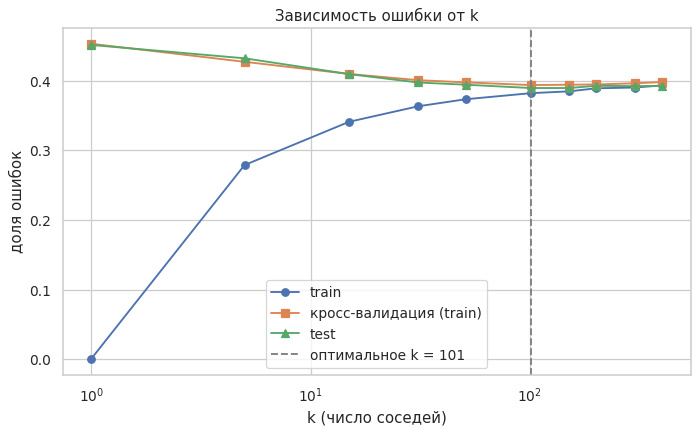

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(res.index, res.train_err, "o-", label="train")
plt.plot(res.index, res.cv_err,    "s-", label="кросс-валидация (train)")
plt.plot(res.index, res.test_err,  "^-", label="test")
best_k = int(res.cv_err.idxmin())
plt.axvline(best_k, color="gray", ls="--", label=f"оптимальное k = {best_k}")
plt.xscale("log"); plt.xlabel("k (число соседей)"); plt.ylabel("доля ошибок"); plt.legend(); plt.title("Зависимость ошибки от k")
plt.show()
print("Оптимальное k по кросс-валидации:", best_k)

In [ ]:
# базовый класс-«константа» для сравнения: всегда предсказываем самый частый класс
majority = y_train.value_counts().idxmax()
print("Ошибка тривиального классификатора (всегда класс %d) на test: %.4f" % (majority, 1 - (y_test == majority).mean()))

final = KNeighborsClassifier(n_neighbors=best_k).fit(Z_train, y_train)
pred_tr, pred_te = final.predict(Z_train), final.predict(Z_test)
print(f"k = {best_k}: ошибка на train = {1 - accuracy_score(y_train, pred_tr):.4f}, на test = {1 - accuracy_score(y_test, pred_te):.4f}")

Ошибка тривиального классификатора (всегда класс 0) на test: 0.4317
k = 101: ошибка на train = 0.3822, на test = 0.3897


Матрица рассогласования (train); строки — истинный класс, столбцы — предсказанный:
[[21400  3519]
 [13242  5689]]

Матрица рассогласования (test); строки — истинный класс, столбцы — предсказанный:
[[5312  918]
 [3354 1379]]

Доля верных ответов по классам (recall) на test:
  Rating < 4.0 : 0.853
  Rating ≥ 4.0 : 0.291
Точность (precision) по классам на test:
  Rating < 4.0 : 0.613
  Rating ≥ 4.0 : 0.600


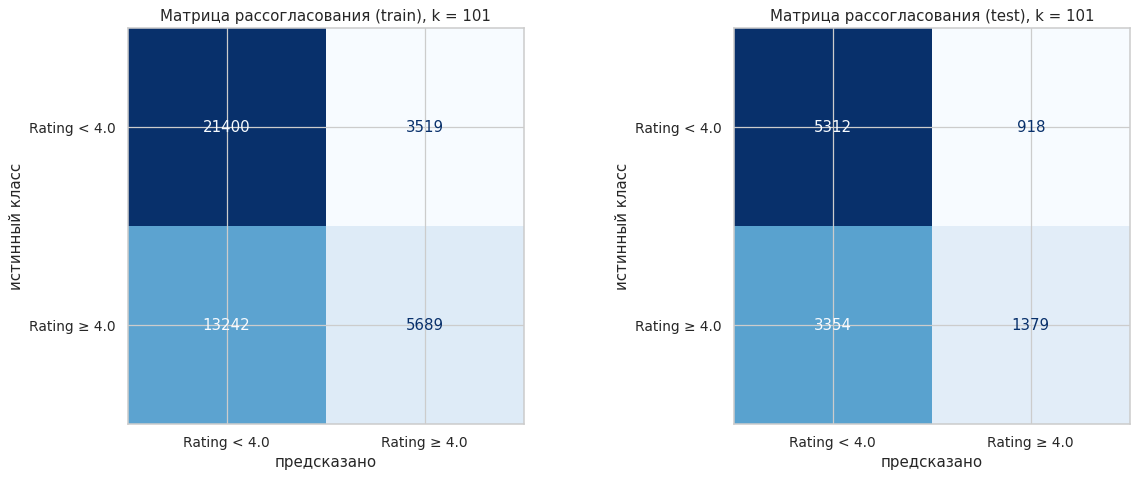

In [ ]:
names = ["Rating < 4.0", "Rating ≥ 4.0"]
for nm, yt, yp in [("train", y_train, pred_tr), ("test", y_test, pred_te)]:
    print(f"Матрица рассогласования ({nm}); строки — истинный класс, столбцы — предсказанный:")
    print(confusion_matrix(yt, yp)); print()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, yt, yp, title in [(axes[0], y_train, pred_tr, "train"), (axes[1], y_test, pred_te, "test")]:
    ConfusionMatrixDisplay(confusion_matrix(yt, yp), display_labels=names).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Матрица рассогласования ({title}), k = {best_k}")
    ax.set_xlabel("предсказано"); ax.set_ylabel("истинный класс")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y_test, pred_te)
print("Доля верных ответов по классам (recall) на test:")
for n, r in zip(names, cm.diagonal() / cm.sum(axis=1)): print(f"  {n:13s}: {r:.3f}")
print("Точность (precision) по классам на test:")
for n, p in zip(names, cm.diagonal() / cm.sum(axis=0)): print(f"  {n:13s}: {p:.3f}")

Комментарий к таблице и графику.
* При `k = 1` ошибка на обучающей выборке почти нулевая (каждая точка — сама себе ближайший сосед, модель «запоминает» выборку), а на тесте — около 45 %, это хуже тривиального классификатора: сильное переобучение.
* С ростом `k` ошибка на обучении растёт, а на кросс-валидации и тесте убывает; кривые сближаются. Минимум ошибки кросс-валидации достигается при `k = 101`, после чего она слегка растёт (модель становится слишком «гладкой», недообучение).
* При оптимальном `k` ошибки на train (≈ 0.38) и test (≈ 0.39) близки — переобучения нет. Ошибка на тесте ≈ 0.39 против 0.43 у тривиального классификатора: выигрыш есть, но небольшой.

Комментарий к матрицам рассогласования. Модель в основном предсказывает класс «Rating < 4.0» (он крупнее): его она находит в ≈ 85 % случаев, а книги с высоким рейтингом — лишь в ≈ 29 % (низкая полнота по классу 1). То есть значительная часть высоко оценённых книг классифицируется как «обычные». Это прямое следствие слабой связи признаков с рейтингом: в окрестности большинства точек классы перемешаны, и голосование соседей почти всегда даёт более частый класс.

## 13. Общие выводы
* Поставлена задача бинарной классификации книг Goodreads (рейтинг ≥ 4.0 или нет) по числу страниц, дате издания, языку, издательству и популярности. Данные разбиты на train/test (80/20, со стратификацией); дальше всё «обучалось» только на train. Исправлена перепутанная пара столбцов (месяц/день), исключены книги без оценок, некорректные значения страниц и года обработаны как выбросы, пропуски заполнены медианой или выделены в категорию `unknown`, категориальные признаки закодированы one-hot (с объединением редких значений), числовые стандартизированы.
* Столбцы `RatingDist1..5` намеренно не использованы: по ним средний рейтинг восстанавливается напрямую.
* Лучший `k = 101` (выбран кросс-валидацией на train). Ошибка на тесте ≈ 0.39 (точность ≈ 61 %), ошибка на train ≈ 0.38. Тривиальный классификатор «всегда класс 0» ошибается в 43 % случаев, так что kNN даёт улучшение примерно на 4 п.п. Малый `k` (1–5) приводит к сильному переобучению.
* Признаки очень слабо связаны с рейтингом (|r| ≲ 0.15), поэтому высокого качества ожидать нельзя: хорошо распознаётся «обычный» класс (полнота ≈ 85 %), а книги с высоким рейтингом находятся плохо (≈ 29 %). Рейтинг книги определяется в основном её содержанием, автором и читательскими вкусами, а этого в использованных признаках нет. Ограничения самого метода: kNN чувствителен к масштабу и числу признаков, медленно работает на больших выборках.